# Datos antes que el modelo: IA centrada en los datos

El módulo 3 empieza con un caso: tres equipos usan la misma red para clasificar flores y obtienen resultados muy distintos, porque cada uno manejó los datos de otra forma. Las lecturas del curso sobre **IA centrada en los datos** (*data-centric AI*) convierten esa observación en un programa de trabajo: en vez de dejar los datos fijos y buscar un modelo mejor, dejar el modelo fijo y mejorar los datos de forma sistemática.

Este notebook lleva esas lecturas a un experimento controlado. Tomamos un conjunto limpio, lo ensuciamos con cuatro problemas que aparecen en datos reales y después comparamos, en la misma prueba limpia, cuánto gana cada mejora **del modelo** y cuánto cada mejora **de los datos**:

- qué entienden por IA centrada en el modelo y centrada en los datos la clase del MIT, el artículo de Jarrahi y otros en *Communications of the ACM* y el survey de Zha y otros;
- un conjunto con etiquetas cambiadas entre clases parecidas, clases escasas, copias repetidas y basura;
- tres mejoras de modelo: una red más grande, más épocas y otra tasa de aprendizaje;
- cuatro detectores de problemas de datos: copias por distancia, basura con las vallas de Tukey, etiquetas malas con **aprendizaje confiado** (*confident learning*) sobre probabilidades fuera de muestra, y el conteo de clases;
- qué tan bien encuentran los problemas que inyectamos (precisión y exhaustividad) y qué encuentran que no inyectamos;
- cuatro arreglos de datos (quitar, corregir, rebalancear, recolectar) y un aumento de datos que sale mal;
- la tabla final y la curva de "más datos contra mejores datos".

Usamos **Fashion-MNIST**, fotos de ropa de 28 × 28 píxeles. El experimento entrena el mismo modelo unas 60 veces; con imágenes de este tamaño, precargadas en memoria, cada entrenamiento toma segundos. Con las flores, cada imagen tiene cientos de píxeles por lado y hay que decodificar un JPEG por foto, así que cada entrenamiento tomaría minutos en una CPU. Las ideas son las mismas.

El notebook tarda unos 7 minutos en una CPU.

**Contenido**

1. Preparación
2. Dos formas de mejorar un sistema
3. Un conjunto de datos sucio
4. El modelo fijo y la línea base
5. Mejorar el modelo
6. Mejorar los datos: copias
7. Mejorar los datos: basura
8. Mejorar los datos: etiquetas
9. Mejorar los datos: clases escasas y aumento
10. Todo junto
11. Más datos contra mejores datos
12. Lo que este experimento no muestra
13. Resumen y ejercicios

## 1. Preparación

Fashion-MNIST tiene 60.000 imágenes de entrenamiento y 10.000 de prueba, en escala de grises, de 10 clases de ropa ([README de Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist#labels)). Sus autores lo pensaron como un reemplazo directo de MNIST, con el mismo tamaño y la misma división, así que `torchvision` lo carga igual. Lo descargamos en `modulo-3/data` y lo dejamos en memoria como tensores, con valores entre 0 y 1.

In [1]:
import time

import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

RAIZ = "../data"
entrenamiento = datasets.FashionMNIST(root=RAIZ, train=True, download=True)
prueba = datasets.FashionMNIST(root=RAIZ, train=False, download=True)

X_todo = entrenamiento.data.float() / 255      # [60000, 28, 28], entre 0 y 1
y_todo = entrenamiento.targets
X_prueba = prueba.data.float() / 255           # [10000, 28, 28]
y_prueba = prueba.targets

CLASES = ["camiseta", "pantalón", "suéter", "vestido", "abrigo",
          "sandalia", "camisa", "zapatilla", "bolso", "botín"]
MEDIA, DESVIACION = X_todo.mean().item(), X_todo.std().item()
print(f"entrenamiento {tuple(X_todo.shape)}   prueba {tuple(X_prueba.shape)}")
print(f"media {MEDIA:.4f}   desviación {DESVIACION:.4f}")
print("imágenes de prueba por clase:", torch.bincount(y_prueba).tolist())

Versión de PyTorch: 2.11.0+cpu


entrenamiento (60000, 28, 28)   prueba (10000, 28, 28)
media 0.2860   desviación 0.3530
imágenes de prueba por clase: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


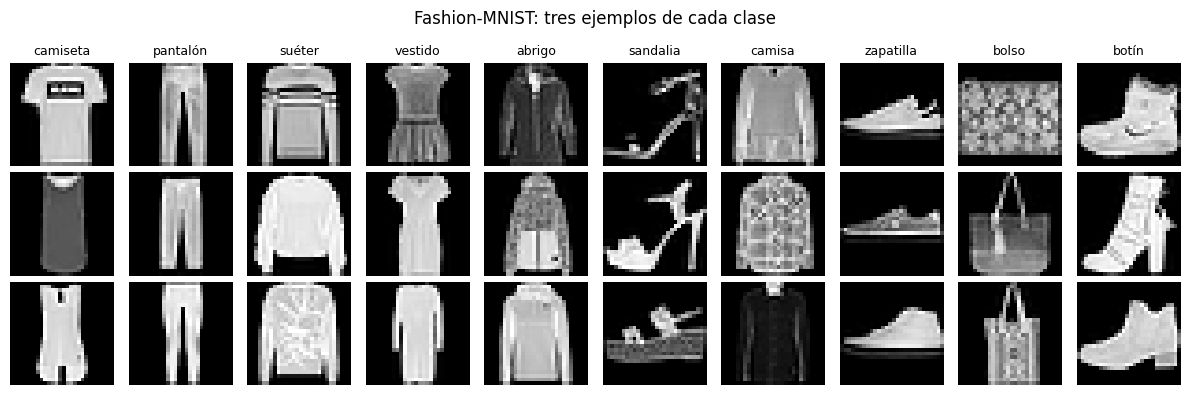

In [2]:
fig, ejes = plt.subplots(3, 10, figsize=(12, 4))
for c in range(10):
    indices = torch.nonzero(y_todo == c).squeeze(1)[:3]
    for fila, i in enumerate(indices.tolist()):
        ejes[fila, c].imshow(X_todo[i], cmap="gray")
        ejes[fila, c].axis("off")
    ejes[0, c].set_title(CLASES[c], fontsize=9)
plt.suptitle("Fashion-MNIST: tres ejemplos de cada clase")
plt.tight_layout()
plt.show()

Algunas clases son fáciles de separar (un pantalón no se parece a nada más) y otras se parecen mucho: camiseta, camisa, suéter y abrigo son prendas de la parte de arriba con mangas; sandalia, zapatilla y botín son calzado. Esas parejas parecidas van a importar en la sección 3.

La prueba tiene 1.000 imágenes de cada clase. Es nuestra **prueba limpia**: no la tocamos, y todas las variantes del experimento se miden en ella.

## 2. Dos formas de mejorar un sistema

La clase *Data-Centric AI vs. Model-Centric AI* del curso del MIT ([2024, primera sección](https://dcai.csail.mit.edu/2024/data-centric-model-centric/)) parte del curso de machine learning típico: te entregan un conjunto de datos bastante limpio y tu trabajo es producir el mejor modelo para él, eligiendo arquitecturas, técnicas de entrenamiento y regularización. A eso lo llama **IA centrada en el modelo**. En el trabajo real, en cambio, los datos no están fijos: se pueden corregir, completar o recolectar. Mejorar los datos de forma sistemática y con algoritmos es la **IA centrada en los datos**. La misma clase lo resume así: la IA centrada en el modelo busca el mejor modelo para un conjunto dado, y la centrada en los datos busca el mejor conjunto para un modelo dado.

Las tres lecturas coinciden en lo central y aportan cosas distintas:

| | Qué aporta |
|---|---|
| Clase del MIT ([página](https://dcai.csail.mit.edu/2024/data-centric-model-centric/) y [diapositivas](https://dcai.csail.mit.edu/2024/data-centric-model-centric/data-centric-model-centric.pdf)) | Una receta en cuatro pasos: explorar y arreglar los datos, entrenar un modelo base, **usar ese modelo para mejorar los datos**, y recién entonces probar modelos distintos. Advierte no saltar del paso 2 al 4. |
| Jarrahi, Memariani y Guha, *The Principles of Data-Centric AI* ([CACM, agosto de 2023](https://arxiv.org/abs/2211.14611v2)) | Seis principios. Los dos primeros son técnicos: mejorar el **ajuste** de los datos al problema (cobertura y balance de clases) y su **consistencia** (que las etiquetas sigan siempre el mismo criterio). El tercero es iterar: mejorar datos y modelo por turnos. |
| Zha y otros, *Data-centric Artificial Intelligence: A Survey* ([arXiv 2303.10158](https://arxiv.org/abs/2303.10158v3)) | Un mapa en tres objetivos ([figura 2, p. 5](https://arxiv.org/pdf/2303.10158v3#page=5)): desarrollar los datos de entrenamiento (recolectar, etiquetar, preparar, reducir y aumentar), desarrollar los datos de inferencia (los que se usan para evaluar el modelo y, en modelos de lenguaje, los *prompts*) y mantener los datos (entenderlos, asegurar su calidad, guardarlos y recuperarlos). Insiste en que no compite con lo anterior: "data-centric AI does not diminish the value of model-centric AI" (sección 2.2). |

El artículo de Jarrahi y otros se publicó en *Communications of the ACM*. La página de la revista no se deja leer sin una cuenta, así que lo citamos por la copia de arXiv, que es la versión publicada (con el número de página de la revista).

Las diapositivas del MIT (diapositiva 9) y la página de la clase enumeran técnicas centradas en los datos. Este notebook prueba cuatro de ellas: detectar y quitar valores atípicos, detectar y corregir errores de etiqueta, aumentar los datos, y lo que Jarrahi llama ajuste de los datos (balance de clases). La diapositiva 8 agrega una precisión útil: duplicar el conjunto de datos y reentrenar *no* es IA centrada en los datos; lo es hacerlo de forma sistemática, por ejemplo con aumento de datos.

## 3. Un conjunto de datos sucio

Partimos de un conjunto limpio y balanceado: 800 imágenes de cada clase, 8.000 en total, sacadas al azar del entrenamiento. Lo que sobra de cada clase queda en una **reserva**, que la sección 9 usa para "recolectar más datos".

In [3]:
N_POR_CLASE = 800
generador = torch.Generator().manual_seed(0)
barajadas = [torch.nonzero(y_todo == c).squeeze(1)[torch.randperm(6000, generator=generador)] for c in range(10)]
indices_limpios = torch.cat([b[:N_POR_CLASE] for b in barajadas])
reserva = {c: barajadas[c][N_POR_CLASE:] for c in range(10)}

X_limpio, y_limpio = X_todo[indices_limpios], y_todo[indices_limpios]
print("conjunto limpio:", len(y_limpio), "imágenes;", "por clase:", torch.bincount(y_limpio).tolist())

conjunto limpio: 8000 imágenes; por clase: [800, 800, 800, 800, 800, 800, 800, 800, 800, 800]


Ahora lo ensuciamos con cuatro problemas. Cada uno imita algo que pasa en datos reales y que las lecturas nombran:

1. **Clases escasas.** Del vestido y la sandalia dejamos solo el 20%. Es el desbalance de la clase del MIT sobre clases desbalanceadas, y lo contrario del "ajuste" de Jarrahi.
2. **Etiquetas cambiadas entre clases parecidas.** El 35% de las camisas queda etiquetado como camiseta, el 35% de los abrigos como suéter y el 35% de los botines como zapatilla, como si una persona apurada confundiera prendas parecidas. No es ruido uniforme: las confusiones van siempre en la misma dirección, como suele pasar en la realidad.
3. **Basura.** 300 imágenes que no son ropa, con etiquetas al azar: 100 negativos (la foto con los colores invertidos, como si viniera de otro escáner), 100 casi vacías (capturas fallidas, con un poco de ruido) y 100 de ruido puro.
4. **Copias.** Un lote de 500 imágenes se importó tres veces más: una copia exacta y dos con un ruido mínimo, de ±2/255 por píxel, como el que deja recomprimir una imagen.

Guardamos dos datos que en la vida real no tendríamos y que aquí sirven para medir: la **etiqueta verdadera** de cada imagen (−1 para la basura) y su **tipo** (bien, etiqueta cambiada, basura o copia).

In [4]:
TIPOS = ["bien", "etiqueta cambiada", "basura", "copia"]
g = torch.Generator().manual_seed(1)
X_sucio, y_sucio, verdad = X_limpio.clone(), y_limpio.clone(), y_limpio.clone()

# 1. Clases escasas: el vestido (3) y la sandalia (5) se quedan con el 20%
conservar = torch.ones(len(y_sucio), dtype=torch.bool)
for c in [3, 5]:
    de_la_clase = torch.nonzero(y_sucio == c).squeeze(1)
    quitar = de_la_clase[torch.randperm(len(de_la_clase), generator=g)[int(0.2 * len(de_la_clase)):]]
    conservar[quitar] = False
X_sucio, y_sucio, verdad = X_sucio[conservar], y_sucio[conservar], verdad[conservar]

# 2. Etiquetas cambiadas: camisa -> camiseta, abrigo -> suéter, botín -> zapatilla, el 35% de cada una
CAMBIOS = [(6, 0), (4, 2), (9, 7)]
for origen, destino in CAMBIOS:
    de_la_clase = torch.nonzero(verdad == origen).squeeze(1)
    elegidas = de_la_clase[torch.randperm(len(de_la_clase), generator=g)[:int(0.35 * len(de_la_clase))]]
    y_sucio[elegidas] = destino
tipo = (y_sucio != verdad).long()                   # 0 bien, 1 etiqueta cambiada

# 3. Basura con etiquetas al azar
modelos = X_limpio[torch.randperm(len(X_limpio), generator=g)[:100]]
negativos = 1 - modelos
vacias = torch.rand(100, 28, 28, generator=g) * 0.04
ruido = torch.rand(100, 28, 28, generator=g)
X_sucio = torch.cat([X_sucio, negativos, vacias, ruido])
y_sucio = torch.cat([y_sucio, torch.randint(0, 10, (300,), generator=g)])
verdad = torch.cat([verdad, torch.full((300,), -1)])
tipo = torch.cat([tipo, torch.full((300,), 2)])

# 4. Un lote de 500 imágenes reales importado tres veces más
importado = torch.randperm(len(y_sucio) - 300, generator=g)[:500]
partes = [X_sucio[importado]] + [(X_sucio[importado] + (torch.rand(500, 28, 28, generator=g) - 0.5) * 4 / 255).clamp(0, 1)
                                 for _ in range(2)]
X_sucio = torch.cat([X_sucio] + partes)
y_sucio = torch.cat([y_sucio] + [y_sucio[importado]] * 3)
verdad = torch.cat([verdad] + [verdad[importado]] * 3)
tipo = torch.cat([tipo] + [torch.full((500,), 3)] * 3)

# Mezclar, para que nada quede en un orden delator
orden = torch.randperm(len(y_sucio), generator=g)
X_sucio, y_sucio, verdad, tipo = X_sucio[orden], y_sucio[orden], verdad[orden], tipo[orden]

print(f"conjunto sucio: {len(y_sucio)} imágenes")
for t, nombre in enumerate(TIPOS):
    print(f"   {nombre:18s} {(tipo == t).sum().item():5d}")
print("\nimágenes por etiqueta (la que dice el conjunto):")
for c in range(10):
    print(f"   {CLASES[c]:10s} {(y_sucio == c).sum().item():5d}")

conjunto sucio: 8520 imágenes
   bien                5880
   etiqueta cambiada    840
   basura               300
   copia               1500

imágenes por etiqueta (la que dice el conjunto):
   camiseta    1376
   pantalón    1009
   suéter      1333
   vestido      227
   abrigo       688
   sandalia     216
   camisa       683
   zapatilla   1310
   bolso       1007
   botín        671


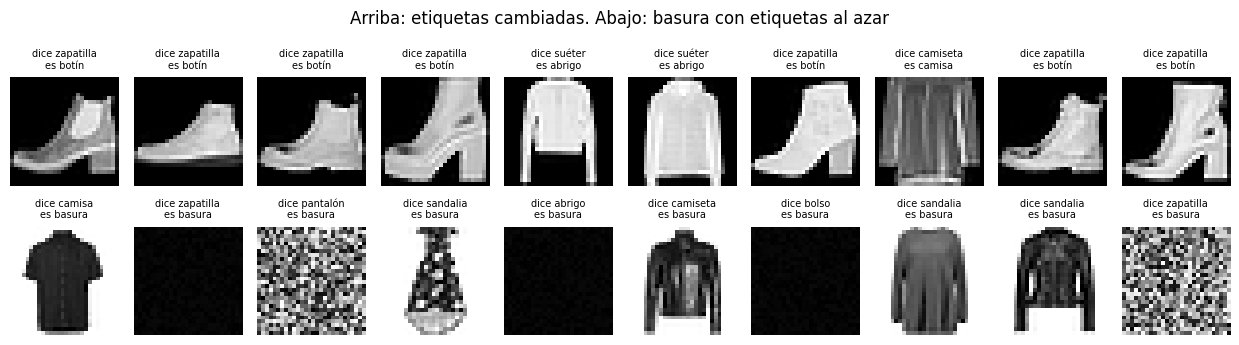

In [5]:
def mostrar(indices, titulos, titulo, columnas=10):
    filas = (len(indices) + columnas - 1) // columnas
    fig, ejes = plt.subplots(filas, columnas, figsize=(1.25 * columnas, 1.85 * filas))
    for eje in ejes.flat:
        eje.axis("off")
    for eje, i, texto in zip(ejes.flat, indices, titulos):
        eje.imshow(X_sucio[i], cmap="gray", vmin=0, vmax=1)
        eje.set_title(texto, fontsize=7)
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()


ejemplos = torch.cat([torch.nonzero(tipo == 1).squeeze(1)[:10], torch.nonzero(tipo == 2).squeeze(1)[:10]])
mostrar(ejemplos.tolist(),
        [f"dice {CLASES[y_sucio[i]]}\nes {CLASES[verdad[i]] if verdad[i] >= 0 else 'basura'}" for i in ejemplos.tolist()],
        "Arriba: etiquetas cambiadas. Abajo: basura con etiquetas al azar")

Arriba, etiquetas cambiadas: botines que dicen zapatilla, abrigos que dicen suéter, una camisa que dice camiseta. Para una persona apurada son confusiones razonables, y por eso las elegimos. Abajo, la basura: negativos (fondo blanco y prenda oscura), capturas casi negras y ruido, cada una con una etiqueta cualquiera.

El conjunto sucio tiene 8.520 imágenes: 5.880 bien, 840 con la etiqueta cambiada, 300 de basura y 1.500 copias (que repiten la etiqueta de su original, cambiada o no). Fíjate en el conteo por etiqueta. Camiseta (1.376), suéter (1.333) y zapatilla (1.310) tienen el doble que camisa (683), abrigo (688) y botín (671). No hay más camisetas que camisas: las etiquetas cambiadas movieron imágenes de una fila a otra. Y vestido (227) y sandalia (216) son las clases escasas.

## 4. El modelo fijo y la línea base

El modelo es el mismo en todo el notebook: una red densa con una capa oculta de 256 neuronas, la misma que usa `05-profundizacion/02_evaluar_mas_alla_de_la_exactitud` del módulo 2. Se entrena 12 épocas con `Adam`, tasa 0.001 y lotes de 256.

Un detalle de la receta: la tasa de aprendizaje baja hasta cero siguiendo un coseno ([`CosineAnnealingLR`](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html)). Llamamos `step()` después de cada lote, así que `T_max`, que la documentación define como "Maximum number of iterations", es el número total de pasos. Al preparar este notebook vimos que, con la tasa fija, la exactitud con etiquetas ruidosas cambiaba varios puntos de una semilla a otra, según dónde quedaba el modelo después del último lote; con la tasa que baja hasta cero, el modelo termina asentado y las semillas quedan a décimas entre sí (el ejercicio 7 te pide comprobarlo). Aun así, cada variante se entrena con **dos semillas** y reportamos la media y la desviación entre ambas, para saber qué diferencias son ruido.

`entrenar` acepta las opciones que usan las secciones siguientes: el tamaño de la red, las épocas, la tasa, aumentar los datos y rebalancear las clases.

In [6]:
def nueva_red(oculta=256, capas=1):
    dimensiones = [784] + [oculta] * capas
    bloques = []
    for entrada, salida in zip(dimensiones[:-1], dimensiones[1:]):
        bloques += [nn.Linear(entrada, salida), nn.ReLU()]
    return nn.Sequential(nn.Flatten(), *bloques, nn.Linear(dimensiones[-1], 10))


def normalizar(x):
    return (x - MEDIA) / DESVIACION


def aumentar(x, g, modo):
    """modo "voltear": voltea al azar la mitad del lote; "desplazar": mueve el lote hasta 2 píxeles; "ambos"."""
    if modo in ("voltear", "ambos"):
        voltear = torch.rand(len(x), generator=g) < 0.5
        x = torch.where(voltear[:, None, None], x.flip(-1), x)
    if modo in ("desplazar", "ambos"):
        dx, dy = torch.randint(-2, 3, (2,), generator=g).tolist()
        x = torch.roll(x, shifts=(dy, dx), dims=(1, 2))
    return x


def entrenar(X, y, oculta=256, capas=1, epocas=12, lr=1e-3, semilla=0, lote=256,
             aumento=None, rebalancear=False):
    torch.manual_seed(semilla)
    g = torch.Generator().manual_seed(semilla)
    modelo = nueva_red(oculta, capas)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    n = len(y)
    pasos = epocas * ((n + lote - 1) // lote)
    programa = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=pasos)
    if rebalancear:                                      # cada clase con la misma probabilidad
        pesos = (1 / torch.bincount(y, minlength=10).float())[y]
    for _ in range(epocas):
        if rebalancear:
            orden = torch.multinomial(pesos, n, replacement=True, generator=g)
        else:
            orden = torch.randperm(n, generator=g)
        for i in range(0, n, lote):
            b = orden[i:i + lote]
            x = aumentar(X[b], g, aumento) if aumento else X[b]
            perdida = F.cross_entropy(modelo(normalizar(x)), y[b])
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()
            programa.step()
    return modelo


@torch.no_grad()
def predecir(modelo, X):
    modelo.eval()
    return modelo(normalizar(X)).argmax(dim=1)


resultados = {}       # nombre -> (media, desviación, exactitud por clase de la primera semilla, n)


def probar(nombre, X, y, semillas=2, **opciones):
    inicio = time.perf_counter()
    exactitudes, por_clase = [], None
    for s in range(semillas):
        prediccion = predecir(entrenar(X, y, semilla=s, **opciones), X_prueba)
        exactitudes.append((prediccion == y_prueba).float().mean().item())
        if por_clase is None:
            por_clase = torch.stack([(prediccion[y_prueba == c] == c).float().mean() for c in range(10)])
    e = torch.tensor(exactitudes)
    desviacion = e.std().item() if semillas > 1 else 0.0
    resultados[nombre] = (e.mean().item(), desviacion, por_clase, len(y))
    print(f"{nombre:40s} {len(y):6d} imágenes   prueba {e.mean():.2%} ± {desviacion:.2%}   "
          f"({time.perf_counter() - inicio:.0f} s)")

Primero los dos extremos: el modelo entrenado con los datos sucios, y el mismo modelo con el conjunto limpio de 8.000 imágenes, que es el mejor resultado al que puede aspirar cualquier limpieza (todo lo que hagamos después usa datos que salen del conjunto sucio, más la reserva en un caso).

In [7]:
probar("sucio", X_sucio, y_sucio)
probar("límite: los datos limpios", X_limpio, y_limpio)

sucio                                      8520 imágenes   prueba 78.44% ± 0.21%   (11 s)


límite: los datos limpios                  8000 imágenes   prueba 84.43% ± 0.40%   (8 s)


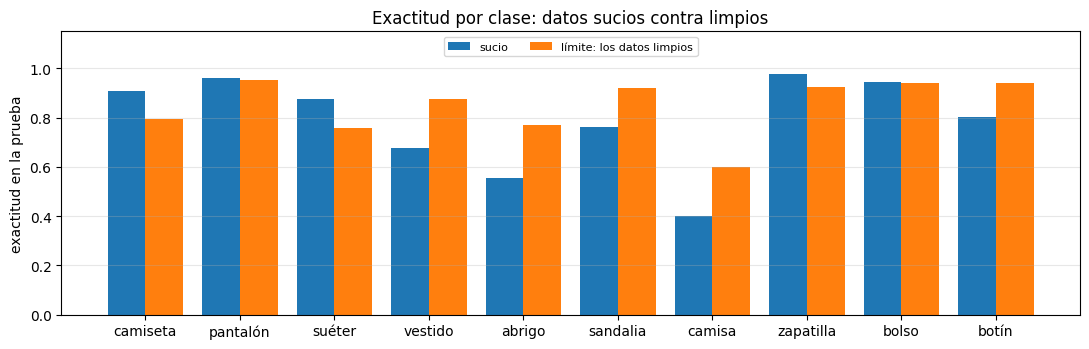

                                        camise  pantal  suéter  vestid  abrigo  sandal  camisa  zapati   bolso   botín
sucio                                    90.8%   96.1%   87.7%   67.7%   55.6%   76.1%   40.0%   97.5%   94.3%   80.1%
límite: los datos limpios                79.4%   95.2%   75.7%   87.4%   77.1%   92.1%   59.8%   92.4%   94.0%   94.0%


In [8]:
def comparar_por_clase(nombres, titulo):
    fig, eje = plt.subplots(figsize=(11, 3.6))
    ancho = 0.8 / len(nombres)
    for k, nombre in enumerate(nombres):
        eje.bar(torch.arange(10) + k * ancho - 0.4 + ancho / 2, resultados[nombre][2], width=ancho, label=nombre)
    eje.set_xticks(range(10))
    eje.set_xticklabels(CLASES)
    eje.set_ylabel("exactitud en la prueba")
    eje.set_ylim(0, 1.15)
    eje.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    eje.grid(axis="y", alpha=0.3)
    eje.legend(loc="upper center", ncol=len(nombres), fontsize=8)
    eje.set_title(titulo)
    plt.tight_layout()
    plt.show()
    print(" " * 38 + "".join(f"{c[:6]:>8s}" for c in CLASES))
    for nombre in nombres:
        print(f"{nombre:38s}" + "".join(f"{v:8.1%}" for v in resultados[nombre][2]))


comparar_por_clase(["sucio", "límite: los datos limpios"], "Exactitud por clase: datos sucios contra limpios")

El modelo con los datos sucios llega a 78.44% en la prueba; con los datos limpios, a 84.45%. Esos seis puntos son lo que cuestan los cuatro problemas juntos, y son el techo de lo que puede recuperar cualquier limpieza. La desviación entre semillas es de décimas (0.21 y 0.44), así que una diferencia de un punto entre variantes no es azar.

Por clase se ve de dónde salen los seis puntos (la tabla usa la primera semilla):

- camisa, abrigo y botín, las clases a las que les cambiamos etiquetas, caen mucho: [CLASE-SUCIO];
- vestido y sandalia, las escasas, también: [ESCASAS-SUCIO];
- y camiseta, suéter y zapatilla, las que recibieron las etiquetas cambiadas, **suben**: [DESTINO-SUCIO]. El modelo aprendió que, ante la duda, conviene decir camiseta, porque en los datos sucios esa etiqueta aparece el doble que camisa. En la prueba, en cambio, hay 1.000 de cada una.

## 5. Mejorar el modelo

El camino centrado en el modelo deja los datos como están y cambia el modelo. Probamos tres cambios típicos, cada uno por separado:

- **una red más grande**: dos capas ocultas de 512 neuronas en vez de una de 256;
- **más épocas**: 24 en vez de 12;
- **otra tasa de aprendizaje**: 0.0003, la que recomienda Full Stack Deep Learning para Adam (`05-profundizacion/01_depurar_un_modelo` del módulo 2, sección 3).

Ninguno se elige mirando la prueba: los tres estaban decididos antes de correr el experimento, y reportamos los tres.

In [9]:
for nombre, red in [("red base", nueva_red()), ("red más grande", nueva_red(512, 2))]:
    print(f"{nombre:15s} {sum(p.numel() for p in red.parameters()):>8,} parámetros".replace(",", "."))
print()
probar("modelo: red más grande", X_sucio, y_sucio, capas=2, oculta=512)
probar("modelo: más épocas", X_sucio, y_sucio, epocas=24)
probar("modelo: tasa 0.0003", X_sucio, y_sucio, lr=3e-4)

red base         203.530 parámetros
red más grande   669.706 parámetros



modelo: red más grande                     8520 imágenes   prueba 80.86% ± 0.01%   (22 s)


modelo: más épocas                         8520 imágenes   prueba 78.67% ± 0.29%   (12 s)


modelo: tasa 0.0003                        8520 imágenes   prueba 75.36% ± 0.33%   (7 s)


La red más grande sube a 80.88%, 2.44 puntos sobre la línea base, con 3.3 veces más parámetros (y cada entrenamiento tarda más: mira los segundos entre paréntesis). Las otras dos no ayudan. Con el doble de épocas queda en 78.69%, dentro del ruido. Con la tasa de 0.0003 baja a 75.37%: con 12 épocas y una tasa que además baja en coseno, al modelo no le alcanza para aprender. Esa tasa es un buen punto de partida, no una regla, y aquí partimos de otra.

El camino del modelo dio un resultado: 2.44 puntos. Ahora veamos qué dan los datos, con la red de 256 neuronas fija.

## 6. Mejorar los datos: copias

Ahora el otro camino. El survey de Zha y otros pone la limpieza de datos dentro de la preparación de los datos de entrenamiento, y entre los métodos tradicionales menciona "scanning all data to find duplicates" ([sección 3.3.2, p. 12](https://arxiv.org/pdf/2303.10158v3#page=12)).

Las copias exactas se encuentran comparando los bytes de cada imagen. Las casi copias, con un poco de ruido, no: sus bytes cambian. Para esas usamos la distancia euclidiana de cada imagen a su vecina más cercana en el conjunto: dos fotos distintas de ropa quedan lejos, y una foto y su copia recomprimida quedan casi encima.

copias exactas (mismos bytes): 500


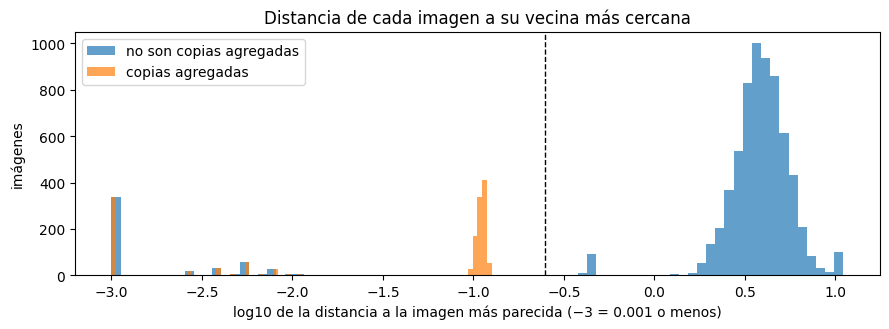

In [10]:
claves = {}
copias_exactas = 0
for fila in (X_sucio * 255).round().to(torch.uint8).flatten(1):
    clave = fila.numpy().tobytes()
    copias_exactas += clave in claves
    claves[clave] = True
print("copias exactas (mismos bytes):", copias_exactas)

plano = X_sucio.flatten(1)
distancia_vecina = torch.empty(len(plano))
for i in range(0, len(plano), 2000):
    d = torch.cdist(plano[i:i + 2000], plano)
    d[torch.arange(len(d)), torch.arange(i, i + len(d))] = float("inf")     # no contra sí misma
    distancia_vecina[i:i + 2000] = d.min(dim=1).values

fig, eje = plt.subplots(figsize=(9, 3.4))
eje.hist(distancia_vecina[tipo != 3].clamp(min=1e-3).log10(), bins=80, alpha=0.7, label="no son copias agregadas")
eje.hist(distancia_vecina[tipo == 3].clamp(min=1e-3).log10(), bins=80, alpha=0.7, label="copias agregadas")
eje.axvline(torch.log10(torch.tensor(0.25)), color="black", linestyle="--", linewidth=1)
eje.set_xlabel("log10 de la distancia a la imagen más parecida (−3 = 0.001 o menos)")
eje.set_ylabel("imágenes")
eje.legend()
eje.set_title("Distancia de cada imagen a su vecina más cercana")
plt.tight_layout()
plt.show()

Las 500 copias exactas tienen los mismos bytes que su original. Las otras 1.000 no, por el ruido, y para esas sirve la distancia. En el histograma hay tres grupos grandes: a la izquierda, por debajo de 0.02, las imágenes idénticas a otra (las copias exactas y también sus originales, que tienen una gemela); cerca de 0.1, las copias con ruido; y a partir de 1.5, todas las demás. Hay dos grupos chicos: unas 100 imágenes cerca de 0.45, las capturas casi vacías, que se parecen entre sí, y unas 100 cerca de 10, el ruido puro, que no se parece a nada. El umbral de 0.25 (la línea punteada) separa las copias de todo lo demás.

¿Por qué una imagen idéntica no da distancia 0? [`torch.cdist`](https://docs.pytorch.org/docs/stable/generated/torch.cdist.html) calcula la distancia euclidiana con una multiplicación de matrices cuando hay más de 25 puntos, que es mucho más rápido pero deja errores de redondeo de centésimas:

In [11]:
iguales = torch.cdist(plano[:30], plano[:30])
print(f"cada imagen contra sí misma, con multiplicación de matrices: hasta {iguales.diagonal().max():.4f}")
exactas = torch.cdist(plano[:30], plano[:30], compute_mode="donot_use_mm_for_euclid_dist")
print(f"cada imagen contra sí misma, restando:                       hasta {exactas.diagonal().max():.4f}")

cada imagen contra sí misma, con multiplicación de matrices: hasta 0.0103
cada imagen contra sí misma, restando:                       hasta 0.0000


Para buscar copias ese error no importa, porque el umbral está muy por encima.

La regla: recorremos el conjunto en orden y marcamos como copia cada imagen que esté a menos de 0.25 de alguna anterior. Así se conserva la primera de cada grupo.

In [12]:
UMBRAL_COPIA = 0.25
es_copia = torch.zeros(len(plano), dtype=torch.bool)
for i in range(0, len(plano), 2000):
    d = torch.cdist(plano[i:i + 2000], plano[:i + 2000])
    filas = torch.arange(i, i + len(d))
    d[torch.arange(d.shape[1])[None, :] >= filas[:, None]] = float("inf")   # solo contra las anteriores
    es_copia[i:i + 2000] = d.min(dim=1).values < UMBRAL_COPIA

print("marcadas como copia:", es_copia.sum().item(), "  copias agregadas:", (tipo == 3).sum().item())
probar("datos: quitar copias", X_sucio[~es_copia], y_sucio[~es_copia])

marcadas como copia: 1500   copias agregadas: 1500


datos: quitar copias                       7020 imágenes   prueba 78.30% ± 0.49%   (5 s)


La regla marca 1.500 imágenes, exactamente las copias que agregamos. Quitarlas deja la exactitud en 78.29%, contra 78.44% con ellas: la diferencia es menor que la variación entre semillas (±0.48). Tiene sentido: las copias no traen información nueva ni falsa, solo hacen que 500 imágenes pesen cuatro veces en el entrenamiento. Su daño está en otra parte, y aparece en la sección 8.

## 7. Mejorar los datos: basura

La clase del MIT sobre desbalance, valores atípicos y cambios de distribución ([sección *Identifying outliers*](https://dcai.csail.mit.edu/2024/imbalance-outliers-shift/)) describe varias formas de encontrar datos atípicos. La más simple son las **vallas de Tukey**: con los cuartiles $Q_1$ y $Q_3$ de una medida, todo lo que cae fuera de $[Q_1 - 1.5\,(Q_3 - Q_1),\; Q_3 + 1.5\,(Q_3 - Q_1)]$ se considera atípico.

Se aplican a un número por imagen, así que primero hay que elegir qué medir. Mirando cómo son las fotos de Fashion-MNIST, dos medidas separan bien la basura:

- el **brillo del borde**: las fotos de ropa tienen fondo negro, así que el borde de 2 píxeles es oscuro; un negativo o una imagen de ruido tienen el borde claro;
- el **contraste** (la desviación estándar de los píxeles): una foto de ropa tiene zonas negras y zonas claras; una captura casi vacía es pareja.

vallas del borde     : [-0.037, 0.220]   fuera: 336
vallas del contraste : [0.099, 0.559]   fuera: 118

marcadas como basura: 452   de ellas son basura: 300 de 300


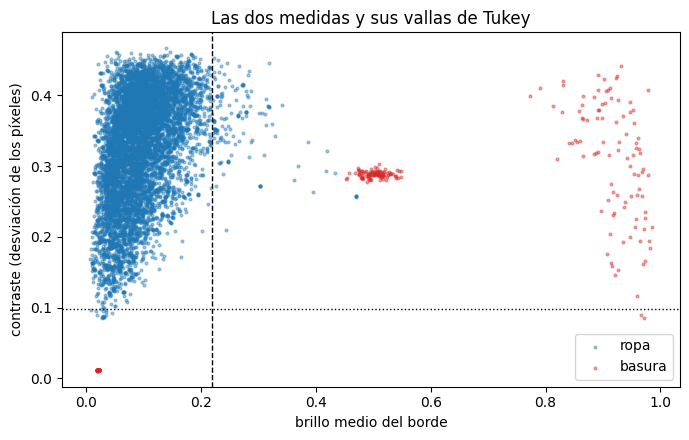

In [13]:
borde = torch.cat([X_sucio[:, :2].flatten(1), X_sucio[:, -2:].flatten(1),
                   X_sucio[:, 2:-2, :2].flatten(1), X_sucio[:, 2:-2, -2:].flatten(1)], dim=1).mean(dim=1)
contraste = X_sucio.flatten(1).std(dim=1)


def fuera_de_las_vallas(valores, k=1.5):
    q1, q3 = torch.quantile(valores, 0.25), torch.quantile(valores, 0.75)
    return (valores < q1 - k * (q3 - q1)) | (valores > q3 + k * (q3 - q1)), (q1 - k * (q3 - q1)).item(), (q3 + k * (q3 - q1)).item()


atipico_borde, *vallas_borde = fuera_de_las_vallas(borde)
atipico_contraste, *vallas_contraste = fuera_de_las_vallas(contraste)
es_basura = atipico_borde | atipico_contraste
print(f"vallas del borde     : [{vallas_borde[0]:.3f}, {vallas_borde[1]:.3f}]   fuera: {atipico_borde.sum().item()}")
print(f"vallas del contraste : [{vallas_contraste[0]:.3f}, {vallas_contraste[1]:.3f}]   fuera: {atipico_contraste.sum().item()}")
print(f"\nmarcadas como basura: {es_basura.sum().item()}   de ellas son basura: {(es_basura & (tipo == 2)).sum().item()} "
      f"de {(tipo == 2).sum().item()}")

fig, eje = plt.subplots(figsize=(7, 4.5))
for t, color in [(0, "tab:blue"), (1, "tab:blue"), (3, "tab:blue"), (2, "tab:red")]:
    m = tipo == t
    eje.scatter(borde[m], contraste[m], s=4, alpha=0.4, color=color,
                label=("basura" if t == 2 else "ropa") if t in (0, 2) else None)
eje.axvline(vallas_borde[1], color="black", linestyle="--", linewidth=1)
eje.axhline(vallas_contraste[0], color="black", linestyle=":", linewidth=1)
eje.set_xlabel("brillo medio del borde")
eje.set_ylabel("contraste (desviación de los píxeles)")
eje.legend()
eje.set_title("Las dos medidas y sus vallas de Tukey")
plt.tight_layout()
plt.show()

Las vallas del borde quedan en [−0.037, 0.220]: casi todas las fotos de ropa tienen el borde más oscuro que 0.22. Las del contraste, en [0.099, 0.559]. Con las dos juntas marcamos 452 imágenes, y entre ellas están las 300 de basura. El gráfico muestra por qué funciona: los negativos (borde cerca de 0.9) y el ruido (borde cerca de 0.5) quedan a la derecha de la valla del borde, y las capturas vacías, con contraste casi 0, quedan bajo la valla del contraste. Las otras 152 marcadas son ropa.

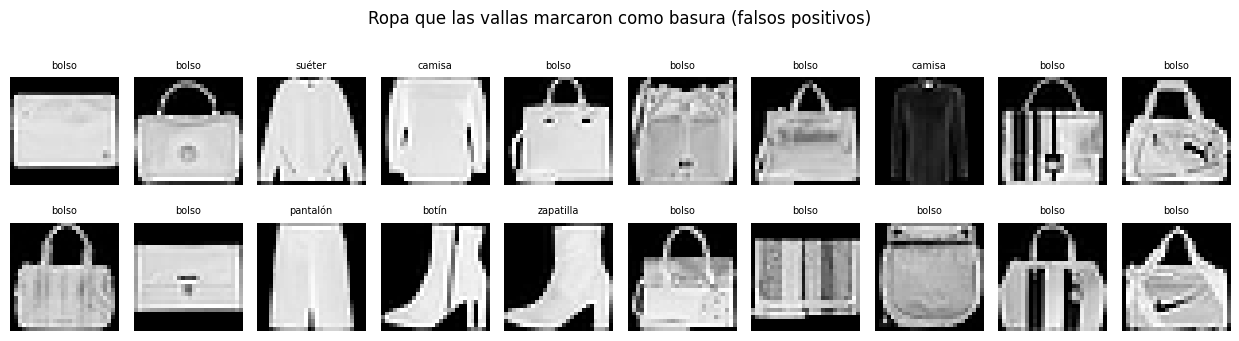

ropa marcada, por etiqueta: {'camiseta': 16, 'pantalón': 2, 'suéter': 18, 'abrigo': 4, 'camisa': 15, 'zapatilla': 4, 'bolso': 82, 'botín': 11}


In [14]:
falsas = torch.nonzero(es_basura & (tipo != 2)).squeeze(1)
mostrar(falsas[:20].tolist(), [CLASES[y_sucio[i]] for i in falsas[:20].tolist()],
        "Ropa que las vallas marcaron como basura (falsos positivos)")
print("ropa marcada, por etiqueta:", {CLASES[c]: (y_sucio[falsas] == c).sum().item()
                                      for c in range(10) if (y_sucio[falsas] == c).any()})

Las prendas marcadas son sobre todo bolsos (82 de 152): un bolso grande llena el cuadro y toca el borde, igual que algunos suéteres y camisas anchos. Son fotos normales, solo menos frecuentes. Es lo que advierte la clase del MIT: no descartar los valores atípicos a ciegas, porque pueden ser casos raros y no datos inválidos; mejor que alguien que conoce el dominio los revise ([sección *Outliers*](https://dcai.csail.mit.edu/2024/imbalance-outliers-shift/)). Jarrahi y otros van más lejos: buscar conjuntos "limpios", sin valores atípicos ni ruido, puede dejar datos que representan peor el mundo real ([p. 89](https://arxiv.org/pdf/2211.14611v2#page=6)). Aquí, quitar las 452 bota 82 de los 1.007 bolsos.

In [15]:
probar("datos: quitar basura", X_sucio[~es_basura], y_sucio[~es_basura])

datos: quitar basura                       8068 imágenes   prueba 78.50% ± 0.11%   (7 s)


Quitar las 452 deja la exactitud en 78.54%, igual que con la basura (78.44%). La basura no se parece a ninguna foto de la prueba, así que lo que el modelo aprende de ella no le estorba con las prendas, y las 152 prendas que se fueron con ella son pocas. Que la exactitud no cambie no vuelve inofensiva a la basura: un modelo en uso va a recibir capturas fallidas y fotos que no son ropa, y conviene detectarlas antes de clasificarlas. La exactitud en una prueba limpia no mide eso.

## 8. Mejorar los datos: etiquetas

El paso 3 de la receta del MIT es usar un modelo entrenado para mejorar los datos. La clase *Label Errors and Confident Learning* ([sección *How does Confident Learning Work?*](https://dcai.csail.mit.edu/2024/label-errors/)) explica el método. Necesita dos cosas: las etiquetas dadas y **probabilidades predichas fuera de muestra**, es decir, de un modelo que no vio ese ejemplo al entrenar. Si el modelo ya vio el ejemplo, su probabilidad para la etiqueta dada tiende a 1 y no delata nada; la primera clase lo advierte: "It is important to train out of sample otherwise the predicted probabilities will overfit to 0 and 1" ([sección *Train step*](https://dcai.csail.mit.edu/2024/data-centric-model-centric/)).

Se obtienen con **validación cruzada**: dividimos el conjunto en 5 partes, entrenamos con 4 y predecimos la quinta, y rotamos hasta tener una predicción para cada ejemplo.

In [16]:
def probabilidades_fuera_de_muestra(X, y, partes=5):
    orden = torch.randperm(len(y), generator=torch.Generator().manual_seed(0))
    probabilidades = torch.zeros(len(y), 10)
    for k in range(partes):
        afuera = orden[k::partes]
        adentro = torch.cat([orden[j::partes] for j in range(partes) if j != k])
        modelo = entrenar(X[adentro], y[adentro], semilla=k)
        modelo.eval()
        with torch.no_grad():
            probabilidades[afuera] = F.softmax(modelo(normalizar(X[afuera])), dim=1)
    return probabilidades


inicio = time.perf_counter()
P_sucio = probabilidades_fuera_de_muestra(X_sucio, y_sucio)
print(f"probabilidades fuera de muestra: {tuple(P_sucio.shape)}   ({time.perf_counter() - inicio:.0f} s)")

probabilidades fuera de muestra: (8520, 10)   (16 s)


Con esas probabilidades, el aprendizaje confiado hace tres cosas, que ya vimos en el módulo 2 aplicadas a la prueba de MNIST (`05-profundizacion/02_evaluar_mas_alla_de_la_exactitud`, sección 6):

1. Para cada clase $j$, el **umbral** $t_j$ es la probabilidad media que el modelo le da a $j$ en los ejemplos etiquetados $j$. La clase lo dice así: "The thresholds for each class are the average predicted probability of examples in that class".
2. Un ejemplo con etiqueta $i$ se cuenta como "probablemente de la clase $j$" si su probabilidad de $j$ llega al umbral $t_j$ (si llega en varias clases, la de mayor probabilidad). Esos conteos forman una matriz de 10 × 10, la **matriz conjunta confiada** $C$: la fila es la etiqueta dada y la columna la clase probable.
3. Los ejemplos fuera de la diagonal de $C$ son las **etiquetas sospechosas**.

Lo nuevo respecto del módulo 2: allá las probabilidades eran de la prueba, que el modelo no había visto. Aquí revisamos el propio **entrenamiento**, y por eso hace falta la validación cruzada. Y como nosotros cambiamos las etiquetas, podemos medir cuántas encuentra.

In [17]:
def aprendizaje_confiado(P, y):
    umbrales = torch.stack([P[y == j, j].mean() for j in range(10)])
    llega = P >= umbrales                                    # [n, 10]
    clase_probable = torch.where(llega, P, torch.full_like(P, -1.0)).argmax(dim=1)
    contado = llega.any(dim=1)
    C = torch.zeros(10, 10, dtype=torch.long)
    for i, j in zip(y[contado].tolist(), clase_probable[contado].tolist()):
        C[i, j] += 1
    sospechosa = contado & (clase_probable != y)
    return umbrales, C, sospechosa, clase_probable


umbrales, C_sucio, sospechosa, clase_probable = aprendizaje_confiado(P_sucio, y_sucio)
print("umbral por clase:")
for c in range(10):
    print(f"   {CLASES[c]:10s} {umbrales[c]:.2f}")

umbral por clase:
   camiseta   0.69
   pantalón   0.92
   suéter     0.62
   vestido    0.55
   abrigo     0.44
   sandalia   0.56
   camisa     0.37
   zapatilla  0.76
   bolso      0.90
   botín      0.59


El umbral de cada clase es la confianza media del modelo en esa etiqueta. Pantalón (0.92) y bolso (0.90) son fáciles. Camisa (0.37) y abrigo (0.44) quedan muy abajo: el modelo duda de esas etiquetas, en parte porque se parecen a camiseta y suéter, y en parte porque las etiquetas cambiadas le enseñaron que una camisa a veces se llama camiseta. Un umbral bajo hace fácil que un ejemplo cuente para esa clase: a una imagen etiquetada camiseta le basta una probabilidad de 0.37 de camisa para quedar como sospechosa (con 0.37 de camisa, a camiseta le queda a lo más 0.63, menos que su umbral de 0.69).

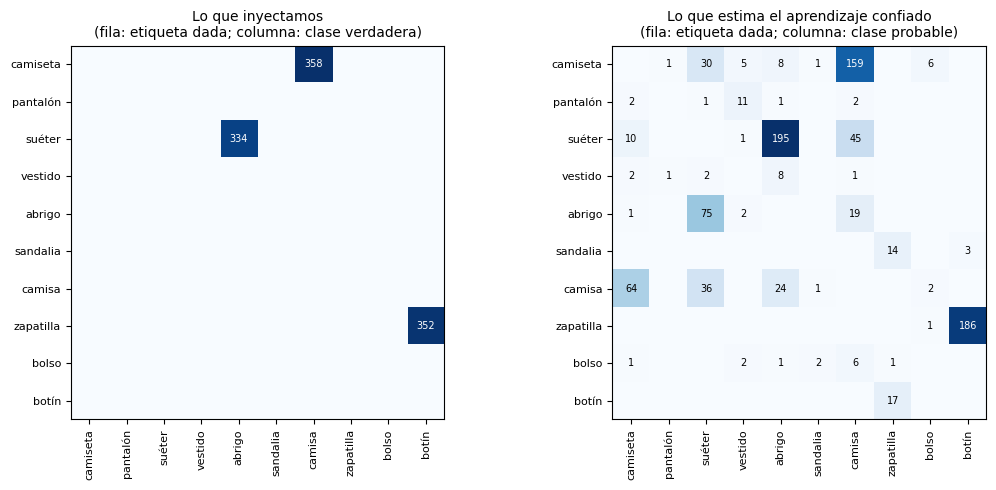

In [18]:
def matriz(ax, M, titulo):
    ax.imshow(M, cmap="Blues")
    for i in range(10):
        for j in range(10):
            if M[i, j] > 0:
                ax.text(j, i, int(M[i, j]), ha="center", va="center", fontsize=7,
                        color="white" if M[i, j] > M.max() / 2 else "black")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xticklabels(CLASES, rotation=90, fontsize=8)
    ax.set_yticklabels(CLASES, fontsize=8)
    ax.set_title(titulo, fontsize=10)


real = torch.zeros(10, 10, dtype=torch.long)                # etiqueta dada contra clase verdadera
for i, j in zip(y_sucio[verdad >= 0].tolist(), verdad[verdad >= 0].tolist()):
    real[i, j] += 1

fuera_de_diagonal = lambda M: M * (1 - torch.eye(10, dtype=torch.long))
fig, ejes = plt.subplots(1, 2, figsize=(11, 5))
matriz(ejes[0], fuera_de_diagonal(real), "Lo que inyectamos\n(fila: etiqueta dada; columna: clase verdadera)")
matriz(ejes[1], fuera_de_diagonal(C_sucio), "Lo que estima el aprendizaje confiado\n(fila: etiqueta dada; columna: clase probable)")
ejes[1].set_ylabel("")
plt.tight_layout()
plt.show()

A la izquierda, lo que hicimos: 358 camisas con la etiqueta camiseta, 334 abrigos con la etiqueta suéter y 352 botines con la etiqueta zapatilla (estas cuentas incluyen las copias, que repiten la etiqueta cambiada). A la derecha, lo que estima el aprendizaje confiado sin saber nada de eso. Las tres celdas más grandes son las mismas: 157, 195 y 185. Encontró la estructura del ruido, aunque subestima cuánto hay.

La matriz de la derecha tiene además celdas en la dirección contraria, que nosotros no tocamos: 76 imágenes etiquetadas abrigo que el modelo cree suéteres y 64 camisas que cree camisetas. En la matriz de la izquierda las filas abrigo y camisa están vacías, así que esas etiquetas son las originales de Fashion-MNIST. Una explicación posible (nuestra): el modelo aprendió de datos donde más de un tercio de los abrigos se llama suéter, y ahora duda también de los abrigos bien etiquetados. El detector usa un modelo entrenado con los mismos datos sucios que queremos limpiar, y hereda parte de su confusión.

In [19]:
def evaluar_detector(marcadas, malas, nombre):
    acierta = (marcadas & malas).sum().item()
    print(f"{nombre}: marca {marcadas.sum().item()}, de ellas {acierta} con la etiqueta cambiada   "
          f"precisión {acierta / marcadas.sum().item():.1%}   exhaustividad {acierta / malas.sum().item():.1%} "
          f"(encontró {acierta} de {malas.sum().item()})")


cambiada = (y_sucio != verdad) & (verdad >= 0)
evaluar_detector(sospechosa, cambiada, "aprendizaje confiado")
print("sugerencia correcta (la clase probable es la verdadera):",
      (sospechosa & cambiada & (clase_probable == verdad)).sum().item(), "de", (sospechosa & cambiada).sum().item())
print("\nsospechosas por tipo:", {TIPOS[t]: (sospechosa & (tipo == t)).sum().item() for t in range(4)})

aprendizaje confiado: marca 950, de ellas 507 con la etiqueta cambiada   precisión 53.4%   exhaustividad 48.6% (encontró 507 de 1044)
sugerencia correcta (la clase probable es la verdadera): 465 de 507

sospechosas por tipo: {'bien': 400, 'etiqueta cambiada': 447, 'basura': 3, 'copia': 100}


El detector marca 946 imágenes, y 503 de ellas tienen la etiqueta cambiada: una **precisión** de 53.2%. De las 1.044 etiquetas cambiadas que hay en el conjunto (las 840 que cambiamos más sus copias), encuentra 503: una **exhaustividad** de 48.2%. Cuando acierta, casi siempre sugiere la clase verdadera: 461 de 503 veces.

Las 400 sospechosas de tipo "bien" tienen la etiqueta que traía Fashion-MNIST. No todas son falsas alarmas, porque Fashion-MNIST tiene sus propias etiquetas dudosas. Estas son las 20 a las que el modelo da menos probabilidad para su etiqueta:

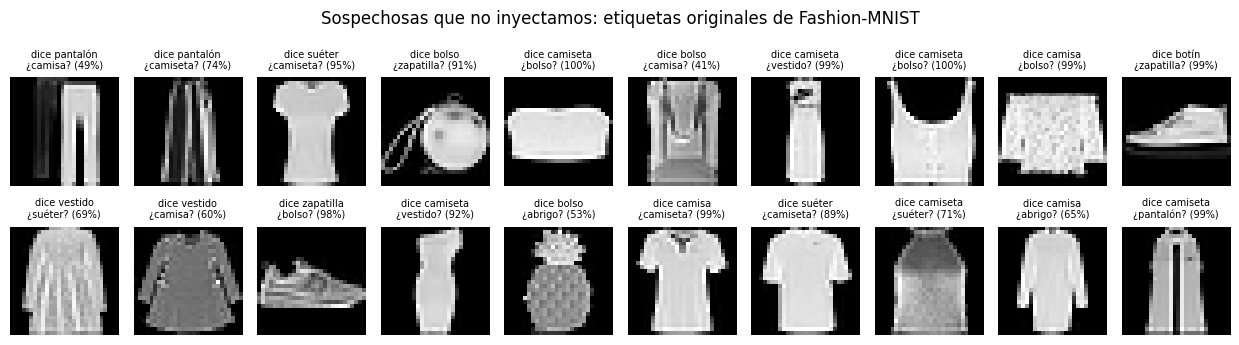

In [20]:
no_inyectadas = torch.nonzero(sospechosa & (tipo == 0)).squeeze(1)
no_inyectadas = no_inyectadas[torch.argsort(P_sucio[no_inyectadas, y_sucio[no_inyectadas]])]   # las más dudosas primero
mostrar(no_inyectadas[:20].tolist(),
        [f"dice {CLASES[y_sucio[i]]}\n¿{CLASES[clase_probable[i]]}? ({P_sucio[i, clase_probable[i]]:.0%})" for i in no_inyectadas[:20].tolist()],
        "Sospechosas que no inyectamos: etiquetas originales de Fashion-MNIST")

Aparecen los mismos tres tipos que vimos con MNIST en `05-profundizacion/02_evaluar_mas_alla_de_la_exactitud` (sección 6) del módulo 2:

- **etiquetas que parecen equivocadas**: dos "suéteres" de manga corta que el modelo ve como camisetas, una "camiseta" larga y angosta que parece un vestido, un "botín" bajo que parece una zapatilla;
- **prendas ambiguas**, que dos personas podrían etiquetar distinto: una camisa tipo polo, de manga corta, que el modelo cree camiseta, o vestidos de manga larga que cree camisa o suéter;
- **errores del modelo**: un bolso redondo con correa que cree zapatilla, una zapatilla que cree bolso y un bolso con forma de piña que cree abrigo.

Fashion-MNIST es difícil también para las personas: el README del conjunto reporta que personas sin experiencia en moda, votando de a tres, aciertan el 83.5% de una muestra de la prueba ([sección *Benchmark*](https://github.com/zalandoresearch/fashion-mnist#benchmark)). Para decidir cuáles de estas son errores de verdad hay que mirarlas, idealmente alguien que conozca de ropa. Es lo que pide el principio 6 de Jarrahi y otros, la interacción continua con expertos del dominio ([p. 90](https://arxiv.org/pdf/2211.14611v2#page=7)).

**Las copias engañan al detector.** La validación cruzada supone que cada ejemplo está en una sola parte. Si una imagen tiene copias, lo más probable es que alguna caiga en las otras 4 partes, así que el modelo que la predice "fuera de muestra" ya vio su copia, con la misma etiqueta. Comparamos cuántas etiquetas cambiadas encuentra según si la imagen tiene copias o no:

In [21]:
tiene_copia = distancia_vecina < UMBRAL_COPIA
for nombre, grupo in [("con copias en el conjunto", tiene_copia), ("sin copias", ~tiene_copia)]:
    malas_del_grupo = cambiada & grupo
    print(f"etiquetas cambiadas {nombre:26s}: {malas_del_grupo.sum().item():4d}   "
          f"encontradas {(sospechosa & malas_del_grupo).sum().item() / malas_del_grupo.sum().item():.1%}")

etiquetas cambiadas con copias en el conjunto :  272   encontradas 29.4%
etiquetas cambiadas sin copias                :  772   encontradas 55.3%


Entre las etiquetas cambiadas de imágenes que tienen copias, el detector encuentra solo el 29.4%; entre las que no tienen, el 54.8%. La copia funciona como una filtración: el modelo que predice el original "fuera de muestra" entrenó con su copia, memorizó la etiqueta equivocada y la repite. Es la misma fuga entre entrenamiento y evaluación de `05-profundizacion/01_fuga_de_datos`, ahora dentro de la validación cruzada. Por eso las copias se quitan antes de buscar errores de etiqueta.


Probamos las dos formas de usar el resultado: **quitar** las sospechosas, que es lo que propone el aprendizaje confiado ("pruning noisy data (as opposed to fixing label errors…)", [sección *What is Confident Learning?*](https://dcai.csail.mit.edu/2024/label-errors/)), y **corregirlas**, cambiando la etiqueta por la clase probable.

In [22]:
probar("datos: quitar etiquetas sospechosas", X_sucio[~sospechosa], y_sucio[~sospechosa])
probar("datos: corregir etiquetas sospechosas", X_sucio, torch.where(sospechosa, clase_probable, y_sucio))

datos: quitar etiquetas sospechosas        7570 imágenes   prueba 79.90% ± 0.01%   (5 s)


datos: corregir etiquetas sospechosas      8520 imágenes   prueba 79.81% ± 0.21%   (6 s)


Quitar las sospechosas sube la exactitud a 79.85%, y corregirlas, a 79.81%: 1.4 puntos las dos. Cada opción tiene su costo. Quitar bota también las 400 sospechosas que estaban bien. Corregir conserva todas las imágenes, pero en esas 400 cambia una etiqueta que estaba bien por otra que probablemente no lo está. Aquí empatan.

Es menos de lo que ganó la red más grande. Con una precisión y una exhaustividad cercanas al 50%, el detector deja la mitad de las etiquetas cambiadas en su lugar, y la mitad de lo que toca estaba bien.

## 9. Mejorar los datos: clases escasas y aumento

El vestido y la sandalia quedaron con 227 y 216 imágenes, contra entre 671 y 1.376 de las demás etiquetas.
 La clase del MIT sobre desbalance ([sección *Training models on imbalanced data*](https://dcai.csail.mit.edu/2024/imbalance-outliers-shift/)) repasa varias soluciones, entre ellas sobremuestrear la clase minoritaria (repetir sus ejemplos) y armar lotes balanceados, que no bota datos. Probamos lotes balanceados: cada imagen se sortea con probabilidad inversa al tamaño de su clase, así que en promedio cada clase aparece lo mismo en cada lote.

Jarrahi y otros agregan la opción que ningún algoritmo reemplaza: **recolectar** datos nuevos. Entre lo que el equipo revisa después de cada iteración está "collect fresh and new data" ([principio 1, p. 87](https://arxiv.org/pdf/2211.14611v2#page=4)). Lo simulamos sacando 640 vestidos y 640 sandalias de la reserva, con sus etiquetas correctas.

In [23]:
print("vestido y sandalia, exactitud en la prueba con los datos sucios:",
      [f"{resultados['sucio'][2][c]:.1%}" for c in [3, 5]])

extra_X = torch.cat([X_todo[reserva[c][:640]] for c in [3, 5]])
extra_y = torch.cat([y_todo[reserva[c][:640]] for c in [3, 5]])

probar("datos: lotes balanceados", X_sucio, y_sucio, rebalancear=True)
probar("datos: recolectar las clases escasas", torch.cat([X_sucio, extra_X]), torch.cat([y_sucio, extra_y]))

vestido y sandalia, exactitud en la prueba con los datos sucios: ['67.7%', '76.1%']


datos: lotes balanceados                   8520 imágenes   prueba 82.31% ± 0.32%   (6 s)


datos: recolectar las clases escasas       9800 imágenes   prueba 81.05% ± 0.40%   (14 s)


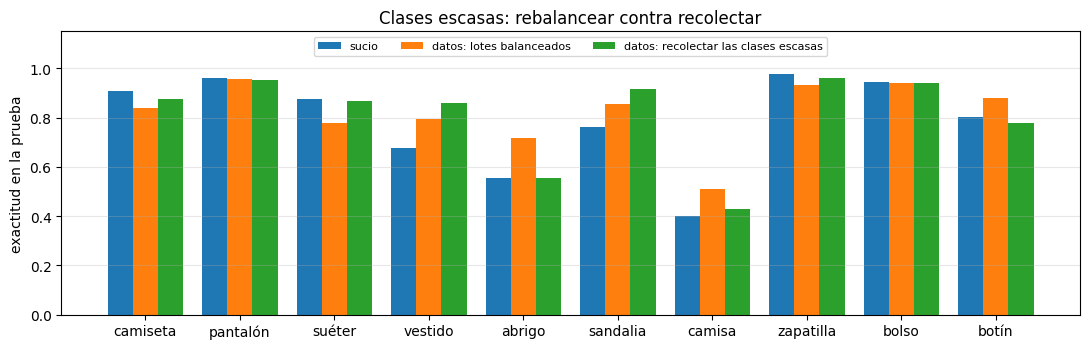

                                        camise  pantal  suéter  vestid  abrigo  sandal  camisa  zapati   bolso   botín
sucio                                    90.8%   96.1%   87.7%   67.7%   55.6%   76.1%   40.0%   97.5%   94.3%   80.1%
datos: lotes balanceados                 83.9%   95.5%   78.0%   79.6%   71.7%   85.7%   51.2%   93.3%   94.0%   87.9%
datos: recolectar las clases escasas     87.7%   95.4%   86.6%   86.0%   55.4%   91.5%   43.0%   95.9%   94.2%   77.7%


In [24]:
comparar_por_clase(["sucio", "datos: lotes balanceados", "datos: recolectar las clases escasas"],
                   "Clases escasas: rebalancear contra recolectar")

Los lotes balanceados suben a 82.28%: 3.85 puntos, el mayor salto de una sola mejora en todo el notebook, más que la red más grande y sin cambiar el modelo ni el costo de entrenarlo. Recolectar sube a 81.11%.

La tabla por clase explica la diferencia. Recolectar arregla justo lo que apunta: [ESCASAS-RECOLECTAR], más que con los lotes balanceados, porque son fotos nuevas y no las mismas 200 repetidas. Pero no toca nada más. Los lotes balanceados, en cambio, también mejoran [ORIGEN-BALANCE], y bajan camiseta, suéter y zapatilla. ¿Por qué, si esas clases no eran escasas? Por las etiquetas cambiadas. En el conjunto sucio la etiqueta camiseta aparece el doble que camisa, y el modelo aprendió esa proporción; los lotes balanceados le muestran todas las etiquetas con la misma frecuencia y deshacen ese sesgo. Se parece a lo que la clase del MIT llama *prior probability shift*: la proporción de clases $p(y)$ cambia entre el entrenamiento y la prueba, aunque cada clase se vea igual ([sección *Prior probability shift / label shift*](https://dcai.csail.mit.edu/2024/imbalance-outliers-shift/)). Rebalancear arregla un síntoma de las etiquetas cambiadas, aunque las etiquetas sigan mal.

### Aumento de datos

El survey define el **aumento de datos** como crear variaciones artificiales de los datos existentes para aumentar su tamaño y diversidad ([sección 3.5](https://arxiv.org/pdf/2303.10158v3#page=15)), y la clase del MIT lo describe como agregar ejemplos "to encode prior knowledge" ([*Examples of data-centric AI*](https://dcai.csail.mit.edu/2024/data-centric-model-centric/)). El conocimiento previo que codificamos aquí es doble: una prenda volteada de izquierda a derecha sigue siendo la misma prenda, y una prenda movida 2 píxeles también. Cada lote se voltea a medias y se desplaza hasta 2 píxeles en cada eje.

In [25]:
probar("datos: aumentar", X_sucio, y_sucio, aumento="ambos")

datos: aumentar                            8520 imágenes   prueba 70.01% ± 0.58%   (9 s)


El aumento **empeora** el resultado: 70.10%, más de ocho puntos menos que sin aumento. Para saber cuál de las dos transformaciones tiene la culpa, las probamos por separado, con una semilla cada una:

In [26]:
probar("aumentar: solo voltear", X_sucio, y_sucio, semillas=1, aumento="voltear")
probar("aumentar: solo desplazar", X_sucio, y_sucio, semillas=1, aumento="desplazar")

aumentar: solo voltear                     8520 imágenes   prueba 77.91% ± 0.00%   (8 s)


aumentar: solo desplazar                   8520 imágenes   prueba 72.45% ± 0.00%   (9 s)


Voltear cuesta medio punto (77.91%); desplazar, seis (72.45%). El problema es el desplazamiento, y la razón está en el modelo. Una red densa tiene un peso distinto para cada píxel y no sabe que el píxel (10, 12) y el (10, 14) son vecinos. Para ella, una prenda movida 2 píxeles es una entrada casi nueva. Aprender las 25 posiciones posibles con el mismo presupuesto de 12 épocas la deja peor en la única posición que aparece en la prueba, donde las prendas no se mueven. El conocimiento previo que codifica el aumento ("es lo mismo, movido") solo sirve si el modelo puede aprovecharlo. Las redes convolucionales del módulo 4 usan los mismos filtros en todas las posiciones; si a ellas el desplazamiento las ayuda no lo medimos aquí.

El survey lo advierte: "there is no single augmentation strategy that is suitable for all scenarios" ([sección 3.5.4, p. 16](https://arxiv.org/pdf/2303.10158v3#page=16)). Un cambio en los datos es una hipótesis, y se mide igual que un cambio en el modelo.

## 10. Todo junto

La receta del MIT encadena los pasos, y el orden importa: las copias se quitan **antes** de la validación cruzada, por lo que vimos en la sección 8, y la basura también, porque sus etiquetas al azar ensucian los umbrales. El pipeline completo, sin datos nuevos:

1. quitar copias y basura;
2. volver a calcular probabilidades fuera de muestra sobre lo que queda y quitar las etiquetas sospechosas;
3. entrenar con lotes balanceados.

El aumento queda fuera, porque en la sección 9 empeoró el resultado. Ojo con esa decisión: la tomamos mirando la prueba. Aquí está bien porque el notebook es un experimento para comparar métodos, pero en un proyecto real esa elección se hace con un conjunto de validación, y la prueba se mira una sola vez al final (`05-profundizacion/01_fuga_de_datos`).

Después, dos variantes: agregar los datos recolectados, y el paso 4 de la receta, probar un modelo distinto (la red más grande) sobre los datos ya mejorados.

In [27]:
queda = ~es_copia & ~es_basura
X_paso1, y_paso1, verdad_paso1, tipo_paso1 = X_sucio[queda], y_sucio[queda], verdad[queda], tipo[queda]
P_paso1 = probabilidades_fuera_de_muestra(X_paso1, y_paso1)
_, _, sospechosa_paso1, _ = aprendizaje_confiado(P_paso1, y_paso1)
evaluar_detector(sospechosa_paso1, (y_paso1 != verdad_paso1) & (verdad_paso1 >= 0), "aprendizaje confiado sin copias ni basura")

X_mejor, y_mejor = X_paso1[~sospechosa_paso1], y_paso1[~sospechosa_paso1]
print(f"quedan {len(y_mejor)} imágenes; se quitaron {(sospechosa_paso1 & (y_paso1 == verdad_paso1)).sum().item()} "
      f"con la etiqueta correcta")
print("imágenes por etiqueta:", torch.bincount(y_mejor, minlength=10).tolist())
print()
probar("datos: todo", X_mejor, y_mejor, rebalancear=True)
probar("datos: todo + recolectar", torch.cat([X_mejor, extra_X]), torch.cat([y_mejor, extra_y]), rebalancear=True)
probar("datos: todo + red más grande", X_mejor, y_mejor, rebalancear=True, capas=2, oculta=512)

aprendizaje confiado sin copias ni basura: marca 898, de ellas 466 con la etiqueta cambiada   precisión 51.9%   exhaustividad 56.0% (encontró 466 de 832)
quedan 5706 imágenes; se quitaron 432 con la etiqueta correcta
imágenes por etiqueta: [869, 786, 826, 145, 423, 139, 390, 904, 728, 496]



datos: todo                                5706 imágenes   prueba 81.96% ± 0.06%   (3 s)


datos: todo + recolectar                   6986 imágenes   prueba 83.36% ± 0.29%   (4 s)


datos: todo + red más grande               5706 imágenes   prueba 82.05% ± 0.01%   (13 s)


variante                                 imágenes         exactitud    cambio
sucio                                        8520   78.44% ± 0.21%    +0.00 pts
modelo: red más grande                       8520   80.86% ± 0.01%    +2.42 pts
modelo: más épocas                           8520   78.67% ± 0.29%    +0.23 pts
modelo: tasa 0.0003                          8520   75.36% ± 0.33%    -3.08 pts
datos: quitar copias                         7020   78.30% ± 0.49%    -0.14 pts
datos: quitar basura                         8068   78.50% ± 0.11%    +0.06 pts
datos: quitar etiquetas sospechosas          7570   79.90% ± 0.01%    +1.46 pts
datos: corregir etiquetas sospechosas        8520   79.81% ± 0.21%    +1.37 pts
datos: lotes balanceados                     8520   82.31% ± 0.32%    +3.87 pts
datos: aumentar                              8520   70.01% ± 0.58%    -8.43 pts
datos: recolectar las clases escasas         9800   81.05% ± 0.40%    +2.61 pts
datos: todo                               

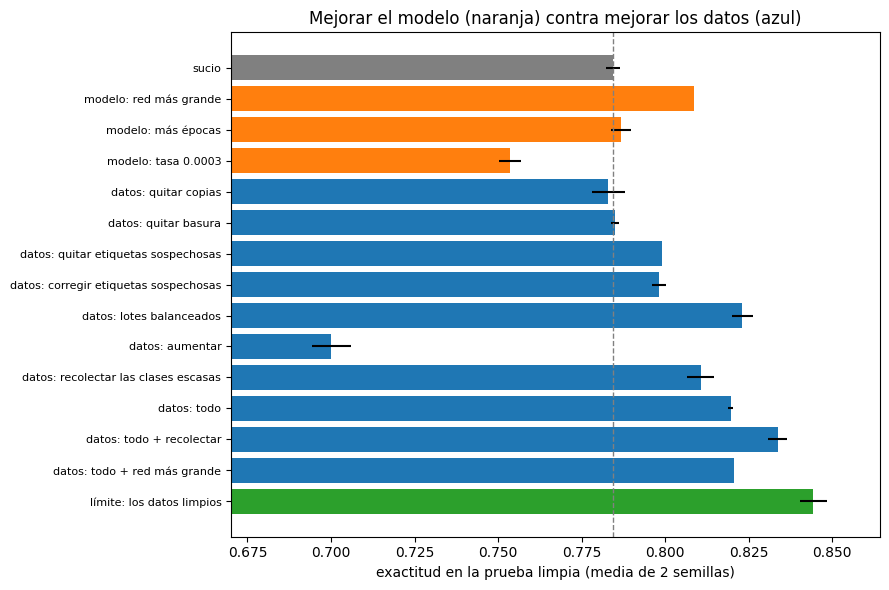

In [28]:
orden_tabla = ["sucio", "modelo: red más grande", "modelo: más épocas", "modelo: tasa 0.0003",
               "datos: quitar copias", "datos: quitar basura", "datos: quitar etiquetas sospechosas",
               "datos: corregir etiquetas sospechosas", "datos: lotes balanceados", "datos: aumentar",
               "datos: recolectar las clases escasas", "datos: todo", "datos: todo + recolectar",
               "datos: todo + red más grande", "límite: los datos limpios"]
base = resultados["sucio"][0]
print(f"{'variante':40s} {'imágenes':>8s} {'exactitud':>17s} {'cambio':>9s}")
for nombre in orden_tabla:
    media, desv, _, n = resultados[nombre]
    print(f"{nombre:40s} {n:8d}   {media:6.2%} ± {desv:.2%}   {100 * (media - base):+6.2f} pts")

fig, eje = plt.subplots(figsize=(9, 6))
colores = ["gray" if n == "sucio" else "tab:orange" if n.startswith("modelo") else
           "tab:green" if n.startswith("límite") else "tab:blue" for n in orden_tabla]
medias = [resultados[n][0] for n in orden_tabla]
desvs = [resultados[n][1] for n in orden_tabla]
eje.barh(range(len(orden_tabla)), medias, xerr=desvs, color=colores)
eje.axvline(base, color="gray", linestyle="--", linewidth=1)
eje.set_yticks(range(len(orden_tabla)))
eje.set_yticklabels(orden_tabla, fontsize=8)
eje.invert_yaxis()
eje.set_xlim(min(medias) - 0.03, max(medias) + 0.02)
eje.set_xlabel("exactitud en la prueba limpia (media de 2 semillas)")
eje.set_title("Mejorar el modelo (naranja) contra mejorar los datos (azul)")
plt.tight_layout()
plt.show()

Sin copias ni basura, el aprendizaje confiado encuentra el 56.0% de las etiquetas cambiadas, contra el 48.2% en el conjunto crudo: es el efecto de quitar las copias antes. (Ahora son 832 y no 1.044 porque las copias de etiquetas cambiadas ya no están.) Jarrahi y otros describen exactamente este ciclo: después de cada iteración, analizar los errores, modificar los datos y volver a evaluar su calidad, y la medida final de esa calidad es el rendimiento del modelo ([p. 86](https://arxiv.org/pdf/2211.14611v2#page=3)).

Lo que dice la tabla:

- **Mejorar el modelo** dio, en el mejor caso, 2.44 puntos (la red más grande). Las otras dos variantes no ayudaron o empeoraron.
- **Una sola mejora de datos**, los lotes balanceados, dio 3.85 puntos. Recolectar dio 2.67, y quitar o corregir etiquetas, 1.4.
- **No todo cambio de datos ayuda.** Quitar copias y basura no movió la exactitud, y el aumento la bajó más de 8 puntos.
- **Las mejoras no se suman.** "Todo" (81.96%) queda por debajo de los lotes balanceados solos (82.28%). Por qué exactamente no lo medimos; dos pistas en las salidas: la limpieza se llevó 432 imágenes con la etiqueta correcta, y camisa y abrigo quedaron con 390 y 423 imágenes, menos de la mitad que camiseta (869) y suéter (826).
- **Datos nuevos y limpieza** dan lo mejor: 83.37%, a 1.1 puntos del límite de los datos limpios (84.45%).
- **El paso 4 de la receta**, la red más grande sobre los datos mejorados, casi no suma: 82.05% contra 81.96%. La misma red ganaba 2.44 puntos con los datos sucios. En este experimento, lo que aportaba la red más grande se superpone con lo que aportan los datos.

La pregunta de la clase del MIT, ¿mejorar el modelo o los datos?, tiene aquí una respuesta clara para este modelo y estos problemas: los datos. Pero la respuesta sale de medir cada cambio, no de elegir un bando.

## 11. Más datos contra mejores datos

Una respuesta habitual a los problemas de datos es juntar más. La diapositiva 8 de la clase del MIT dice que duplicar el tamaño del conjunto y reentrenar no es, por sí solo, IA centrada en los datos. La pregunta que sí se puede medir es cuánto vale cada cosa: ¿cuántas imágenes con etiquetas ruidosas equivalen a una cantidad dada de imágenes bien etiquetadas?

Entrenamos el mismo modelo con conjuntos balanceados de 1.000 a 8.000 imágenes del entrenamiento completo, una vez con las etiquetas originales y otra con el mismo ruido de la sección 3 (35% de camisas, abrigos y botines con la etiqueta de la clase parecida). Para que los conjuntos chicos no queden con muy pocos pasos de entrenamiento, cada uno se entrena al menos 375 pasos, lo mismo que 12 épocas de 8.000 imágenes. Una semilla por punto: con la tasa que baja en coseno, la variación entre semillas es de décimas.

  1000 imágenes ( 96 épocas)   etiquetas originales 80.56%   con ruido 74.85%


  2000 imágenes ( 48 épocas)   etiquetas originales 81.83%   con ruido 77.98%


  4000 imágenes ( 24 épocas)   etiquetas originales 83.75%   con ruido 78.98%


  8000 imágenes ( 12 épocas)   etiquetas originales 84.51%   con ruido 80.04%
(29 s)


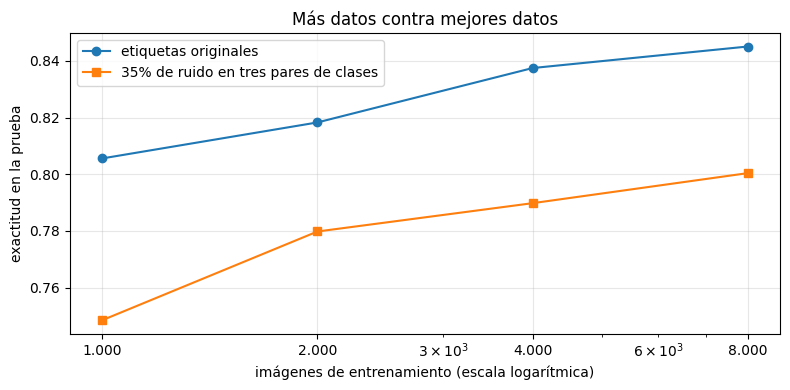

In [29]:
def conjunto_balanceado(n, con_ruido, semilla=2):
    g = torch.Generator().manual_seed(semilla)
    indices = torch.cat([torch.nonzero(y_todo == c).squeeze(1)[torch.randperm(6000, generator=g)[:n // 10]] for c in range(10)])
    y = y_todo[indices].clone()
    if con_ruido:
        for origen, destino in CAMBIOS:
            de_la_clase = torch.nonzero(y_todo[indices] == origen).squeeze(1)
            y[de_la_clase[torch.randperm(len(de_la_clase), generator=g)[:int(0.35 * len(de_la_clase))]]] = destino
    return X_todo[indices], y


tamanos = [1000, 2000, 4000, 8000]
curva = {False: [], True: []}
inicio = time.perf_counter()
for n in tamanos:
    epocas = max(12, -(-375 * 256 // n))           # al menos 375 pasos de 256
    for con_ruido in (False, True):
        X_n, y_n = conjunto_balanceado(n, con_ruido)
        prediccion = predecir(entrenar(X_n, y_n, epocas=epocas), X_prueba)
        curva[con_ruido].append((prediccion == y_prueba).float().mean().item())
    print(f"{n:6d} imágenes ({epocas:3d} épocas)   etiquetas originales {curva[False][-1]:.2%}   "
          f"con ruido {curva[True][-1]:.2%}")
print(f"({time.perf_counter() - inicio:.0f} s)")

fig, eje = plt.subplots(figsize=(8, 4))
eje.plot(tamanos, curva[False], marker="o", label="etiquetas originales")
eje.plot(tamanos, curva[True], marker="s", label="35% de ruido en tres pares de clases")
eje.set_xscale("log")
eje.set_xticks(tamanos)
eje.set_xticklabels([f"{n:,}".replace(",", ".") for n in tamanos])
eje.set_xlabel("imágenes de entrenamiento (escala logarítmica)")
eje.set_ylabel("exactitud en la prueba")
eje.grid(alpha=0.3)
eje.legend()
eje.set_title("Más datos contra mejores datos")
plt.tight_layout()
plt.show()

Con las etiquetas originales, 1.000 imágenes dan 80.56%. Con el ruido, ni 8.000 llegan ahí: 80.04%. En este experimento, **8.000 imágenes con ruido rinden menos que 1.000 bien etiquetadas**. La curva con ruido sube con cada duplicación, así que más datos ruidosos también ayudan, pero queda entre 3.8 y 5.7 puntos por debajo de la limpia en todos los tamaños.

Es lo que plantean Jarrahi y otros: el principio 2 pone la exactitud y la consistencia de los datos por sobre "its sheer volume" ([p. 87](https://arxiv.org/pdf/2211.14611v2#page=4)), y la conclusión dice que la IA centrada en los datos "gives precedence to the quality of data over its size" ([p. 91](https://arxiv.org/pdf/2211.14611v2#page=8)). Este es un caso donde eso se puede medir.

## 12. Lo que este experimento no muestra

- **Sabemos dónde está cada problema** porque los pusimos nosotros, y por eso podemos medir precisión y exhaustividad. Con datos reales no hay `verdad` ni `tipo`: lo que marca un detector hay que revisarlo a mano.
- **El ruido es simple**: tres pares de clases, siempre en la misma dirección, 35%. Los errores reales mezclan muchas causas, y el aprendizaje confiado los encuentra mejor o peor según cómo sean.
- **Un solo modelo, y chico.** Con una red convolucional los números cambian, y quizá también la conclusión sobre el aumento.
- **Decidimos mirando la prueba.** Dejar el aumento fuera de "todo" salió de comparar en la prueba; en un proyecto real eso se hace con validación.
- **La prueba está balanceada.** Los lotes balanceados ganan en parte porque la prueba tiene 1.000 imágenes de cada clase. Si en el uso real hubiera pocos vestidos, entrenar con la proporción real podría ser mejor. La clase del MIT lo dice así: si entrenar con la distribución real funciona bien en una prueba que se parece al mundo real, "then you’re done!" ([sección *Training models on imbalanced data*](https://dcai.csail.mit.edu/2024/imbalance-outliers-shift/)).
- **Dos semillas por variante** alcanzan para separar diferencias de un punto o más. Diferencias de décimas, como entre quitar y corregir etiquetas, son ruido.
- **Lo humano no se mide aquí.** Los principios 4 a 6 de Jarrahi y otros (el trabajo con datos como algo humano, la IA como sistema sociotécnico y la interacción con expertos del dominio) no caben en un experimento como este, y son la mitad de su artículo.

## 13. Resumen

- La IA centrada en el modelo busca el mejor modelo para un conjunto dado; la centrada en los datos, el mejor conjunto para un modelo dado. Las lecturas del curso no las oponen: la receta del MIT pide mejorar los datos con ayuda de un modelo **antes** de probar modelos distintos.
- En un conjunto con cuatro problemas inyectados, la mejor mejora de modelo (una red más grande) ganó 2.44 puntos. Los lotes balanceados ganaron 3.85, y la limpieza más datos nuevos, 4.93, a 1.1 puntos del límite de los datos limpios.
- Las copias no bajan la exactitud, pero engañan a la validación cruzada: el aprendizaje confiado encontró el 29.4% de las etiquetas cambiadas con copias, contra el 54.8% sin copias. Se quitan antes de buscar errores.
- Las vallas de Tukey encontraron toda la basura, pero también 152 prendas, sobre todo bolsos. Los atípicos se revisan; no se botan a ciegas.
- El aprendizaje confiado, con probabilidades fuera de muestra, encontró la estructura del ruido (las tres celdas grandes de la matriz) con una precisión y una exhaustividad cercanas al 50%. Lo que marca sin que lo hayamos inyectado mezcla errores de Fashion-MNIST, prendas ambiguas y errores del modelo.
- Un cambio de datos es una hipótesis: desplazar las imágenes le quitó 6 puntos a una red densa. Y las mejoras no se suman: hay que medir las combinaciones.
- 8.000 imágenes con 35% de ruido en tres pares de clases rinden menos que 1.000 bien etiquetadas.


## Ejercicios

1. **Predice y comprueba.** Sube el ruido de etiquetas de 35% a 45% en los tres pares (`CAMBIOS`) y vuelve a correr las secciones 3, 4 y 8. Antes de correr, anota qué esperas para la exactitud de "sucio" y para la precisión y la exhaustividad del aprendizaje confiado. ¿Qué pasaría con 55%, cuando la mayoría de las camisas dice "camiseta"? Pista: el umbral de cada clase es el promedio de las probabilidades de los ejemplos con esa etiqueta.
2. Implementa la variante de la clase del MIT para marcar etiquetas: normaliza la matriz $C$ para que sume 1, multiplícala por el número de ejemplos y, en cada celda fuera de la diagonal, marca solo esa cantidad de ejemplos, los de mayor probabilidad de la clase de la columna. Compara precisión y exhaustividad con la versión de este notebook.
3. Las vallas de Tukey marcaron ropa de verdad. La clase del MIT propone también la distancia a los $k$ vecinos más cercanos. Calcula para cada imagen la distancia media a sus 5 vecinas (reutiliza el bucle de `torch.cdist` de la sección 6, sin contar las copias), marca las 300 más lejanas y compara cuánta basura encuentra y cuánta ropa marca por error.
4. **Predice y comprueba.** Entrena el conjunto limpio de 8.000 imágenes con `aumento="voltear"` y con `aumento="desplazar"`. ¿El desplazamiento también empeora el resultado cuando las etiquetas están bien? ¿Y con 36 épocas en vez de 12?
5. En "datos: todo", cambia "quitar las sospechosas" por "corregirlas" (la clase probable como etiqueta nueva). ¿Cambia el resultado? ¿Cuántas de las correcciones son correctas, según `verdad`?
6. Rehaz la curva de la sección 11 con 20% de ruido en vez de 35%, y agrega 16.000 a `tamanos`. ¿Cuántas imágenes con ruido hacen falta ahora para igualar a 1.000 bien etiquetadas? ¿Y a 2.000?
7. Quita el `CosineAnnealingLR` de `entrenar` (la tasa queda fija en 0.001) y entrena "sucio" con 5 semillas. Compara la desviación entre semillas con la de la sección 4, y la de "límite: los datos limpios" con la tasa fija. ¿Por qué el ruido de etiquetas hace que el resultado dependa más de dónde termina el entrenamiento?

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026.

**Del material del curso**

- **MIT, *Introduction to Data-Centric AI*** (IAP 2024), clase [*Data-Centric AI vs. Model-Centric AI*](https://dcai.csail.mit.edu/2024/data-centric-model-centric/):
  - Introducción: "your job is to produce the best model for this dataset" y "We call this paradigm model-centric AI"; "Contrary to the classroom, the data are not fixed in real-world applications!"; "Seasoned data scientists know it is more worthwhile to invest in exploring and fixing the data than tinkering with models"; sobre las dos formas de la IA centrada en los datos: "Confident learning is an example of this, in which ML models are trained on a filtered dataset where mislabeled data has been removed".
  - *A practical recipe for supervised Machine Learning*: "model-centric AI is based on the goal of producing the best model for a given dataset, whereas data-centric AI is based on the goal of systematically & algorithmically producing the best dataset to feed a given ML model"; los cuatro pasos, entre ellos "Utilize this model to help you improve the dataset" y "Try different modeling techniques to improve the model on the improved dataset and obtain the best model"; y "Remember not to skip straight from Step 2 to Step 4 even though it is tempting!"
  - *Examples of data-centric AI*: "Outlier detection and removal (handling abnormal examples in dataset)", "Error detection and correction (handling incorrect values/labels in dataset)" y "Data augmentation (adding examples to data to encode prior knowledge)".
  - *Putting it all together: PU Learning Algorithm*, paso *Train step*: "It is important to train out of sample otherwise the predicted probabilities will overfit to 0 and 1 since the classifier has already seen the data."
  - [Diapositivas de la clase](https://dcai.csail.mit.edu/2024/data-centric-model-centric/data-centric-model-centric.pdf): diapositiva 6, "Given a dataset, try to produce the best model" y "Given any model, try to improve the training dataset"; diapositiva 8, *What is not data-centric AI?*: "Double the size of your dataset and train an improved model on more data", con sus versiones centradas en los datos, "Coreset selection" y "Dataset Augmentation"; diapositiva 9, la lista de ejemplos.
- **Jarrahi, Memariani y Guha**, [*The Principles of Data-Centric AI*](https://arxiv.org/abs/2211.14611v2), *Communications of the ACM* 66(8), agosto de 2023, pp. 84–92. La página de la revista respondió con un error 403 al abrirla; leímos la versión 2 de arXiv, que es el PDF publicado en la revista, con su paginación:
  - p. 84: "The primary goal of model-centric AI has been to improve model performance via optimizing the learning parameters and hyper-parameters of a given model."
  - p. 86 (la iteración de la figura 2): "After each iteration, three typical steps need to be taken. In the first step, the team conducts error analysis"; el tercer paso evalúa la calidad de los datos, y entre las estrategias está "monitoring the improvements in the performance of the AI model itself, which is the ultimate measure of data quality in developing AI systems".
  - p. 87, principio 1 (*Systematic Improvement of Data Fit*): "the data balance (for example, evenly distributed number of samples from each class and absence of biases that can adversely affect the model’s performance)"; "the DCAI team may examine if there is a need to clean and better prepare existing data; generate synthetic data via data augmentation; or collect fresh and new data".
  - p. 87, principio 2 (*Systematic Improvement of Data Consistency*): "the accuracy or consistency of data rather than its sheer volume" y "data consistency refers to the adherence to the same procedure of annotation across annotators and over time".
  - p. 88, principio 3 (*Mutual Improvement of Model and Data through Iteration*): "Error analysis of the model after each iteration determines what subsets of the data are acceptable or unacceptable in relation to the model’s performance".
  - p. 89: "ML engineers may often aim for collecting “clean” datasets which are free from outliers and so-called “noise” to improve the model performance. This urge could result in “overfitting,” which inevitably lowers the representativeness of data".
  - p. 91, conclusión: la IA centrada en los datos "gives precedence to the quality of data over its size".
- **Zha, Bhat, Lai, Yang, Jiang, Zhong y Hu**, [*Data-centric Artificial Intelligence: A Survey*](https://arxiv.org/abs/2303.10158v3) (arXiv, versión 3, 11 de junio de 2023):
  - Sección 1, p. 2: "In the conventional model-centric AI lifecycle, researchers and developers primarily focus on identifying more effective models to improve AI performance while keeping the data largely unchanged" y "data-centric AI emphasizes the systematic engineering of data to build AI systems".
  - Sección 2.1, p. 4: "Data-centric AI refers to a framework to develop, iterate, and maintain data for AI systems".
  - Sección 2.2, p. 5: "data-centric AI does not diminish the value of model-centric AI".
  - Figura 2, p. 5 (*Data-centric AI framework*), y sección 2.3: "We divide data-centric AI into three goals: training data development, inference data development, and data maintenance".
  - Sección 3.3.2, p. 12: entre los métodos tradicionales, "scanning all data to find duplicates", y entre los que usan aprendizaje, "correcting labeling errors".
  - Sección 3.5, p. 15: "Data augmentation is a technique to increase the size and diversity of data by artificially creating variations of the existing data, which can often improve the model performance."
  - Sección 3.5.4, p. 16: "there is no single augmentation strategy that is suitable for all scenarios".

**Otras clases del mismo curso del MIT** (no están en la lista del curso, pero continúan la clase que sí está)

- [*Label Errors and Confident Learning*](https://dcai.csail.mit.edu/2024/label-errors/): en *What is Confident Learning?*, "CL is based on the principles of pruning noisy data (as opposed to fixing label errors or modifying the loss function)" y sus dos insumos, "out-of-sample predicted probabilities" y "noisy labels"; en *Benefits of Confident Learning*, "We use cross-validation to obtain predicted probabilities out-of-sample."; en *How does Confident Learning Work?*, "The thresholds for each class are the average predicted probability of examples in that class."; en *Find label issues using the joint distribution of label noise*, la variante que multiplica la distribución conjunta por el número de ejemplos y marca, en cada celda fuera de la diagonal, los ejemplos más probables ("Repeat for all non-diagonal entries in the matrix").
- [*Class Imbalance, Outliers, and Distribution Shift*](https://dcai.csail.mit.edu/2024/imbalance-outliers-shift/): en *Training models on imbalanced data*, "If training a model on the true distribution works well, i.e., the model scores highly on the evaluation metric over a held-out test set that matches the real-world distribution, then you’re done!"; sobre el sobremuestreo, "often performs better than sample weights. This solution is often unstable, and it can result in overfitting"; y "Balanced mini-batch training. [...] you can include datapoints from minority classes with higher probability, such that the mini-batch is balanced. This approach is similar to over-sampling, and it does not throw away data." En *Outliers*: "you don’t want to blindly discard them: they might be rare events rather than invalid data points. You could, for example, have a domain expert manually review outliers". En *Identifying outliers*, las vallas de Tukey: "A multiplier of k=1.5 was proposed by John Tukey." (la página escribe el extremo inferior como $Q_1 - k(Q_1 - Q_3)$, una errata: el extremo es $Q_1 - k(Q_3 - Q_1)$, como en la sección 7).

**Del conjunto de datos**

- **Zalando Research**, [README de Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist): "a training set of 60,000 examples and a test set of 10,000 examples. Each example is a 28x28 grayscale image, associated with a label from 10 classes" y "a direct drop-in replacement for the original MNIST dataset"; sección *Labels*, la tabla de las 10 clases (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot).

**Documentación de PyTorch**

- [`torch.optim.lr_scheduler.CosineAnnealingLR`](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html): "Set the learning rate of each parameter group using a cosine annealing schedule"; `T_max`: "Maximum number of iterations".
- [`torch.multinomial`](https://docs.pytorch.org/docs/stable/generated/torch.multinomial.html): "The rows of input do not need to sum to one (in which case we use the values as weights)" y "If replacement is True, samples are drawn with replacement."
- [`torch.cdist`](https://docs.pytorch.org/docs/stable/generated/torch.cdist.html): "Computes the batched p-norm distance between each pair of the two collections of row vectors."
- [`torch.roll`](https://docs.pytorch.org/docs/stable/generated/torch.roll.html): "Elements that are shifted beyond the last position are re-introduced at the first position."

**Lo que no viene de una fuente** son los números de este notebook (exactitudes, conteos, umbrales, precisión y exhaustividad de cada detector): todos salen de las celdas de código. También son nuestros el diseño del experimento (los cuatro problemas y sus proporciones, el umbral de 0.25 para las copias, el brillo del borde y el contraste como medidas para las vallas de Tukey), la observación de que los lotes balanceados también deshacen la distorsión de clases que crean las etiquetas cambiadas, y la explicación de por qué desplazar las imágenes perjudica a una red densa.